# Módulo 4 — Práctica Día 6: apertura, mapas y viento

Ejercicios de la práctica del **Día 6** (ver [`README.md`](../README.md)).
Trabajamos con el `wrfout` real recortado (`data/grid_muestra/`, ver
[`01_teoria_demos.ipynb`](01_teoria_demos.ipynb)) — dominio real de
Argentina/Uruguay/sur de Brasil, 3 pasos de tiempo (06, 08, 10 UTC del
2024-12-13) — y, en el Ejercicio 4, un segundo producto real
(`wrfpress_muestra.nc`), la misma corrida post-procesada a niveles de
presión estándar.

> **📍 Nota para curso con 2 grupos:** el `wrfout` es el mismo para ambos grupos (no se puede recortar una corrida ya hecha). En el mapa del Ejercicio 2, cada grupo marca sobre su mapa la ubicación real de sus 3 estaciones asignadas (`data/ogimet/coords_area_wrf.json`):
> - **Grupo 1 (Norte):** Iguazú, Resistencia, Salto.
> - **Grupo 2 (Sur):** Rosario, Ezeiza, Carrasco.
> ```python
> import json
> coords = json.load(open("../../../data/ogimet/coords_area_wrf.json"))
> estaciones_grupo = ["Iguazu", "Resistencia", "Salto"]  # o el trío del Grupo 2
> for nombre in estaciones_grupo:
>     c = coords[nombre]
>     ax.plot(c["lon"], c["lat"], "k^", markersize=8, transform=ccrs.PlateCarree())
>     ax.annotate(nombre, (c["lon"], c["lat"]), transform=ccrs.PlateCarree(), fontsize=8)
> ```
> (agregar después de `ax.gridlines(...)` en el Ejercicio 2)

## Ejercicio 1 — Primera apertura con xwrf (40 min)

In [1]:
import xarray as xr
import xwrf
import numpy as np

raw = xr.open_dataset("../../../data/grid_muestra/wrfout_real_muestra.nc")
ds = raw.xwrf.postprocess().xwrf.destagger()

print("Dimensiones ANTES  de xwrf: U ->", raw["U"].dims, raw["U"].shape)
print("Dimensiones DESPUÉS de xwrf: U ->", ds["U"].dims, ds["U"].shape)
print()
print("Atributos de proyección detectados:")
for k in ["MAP_PROJ", "TRUELAT1", "CEN_LAT", "CEN_LON"]:
    print(f"  {k}: {raw.attrs[k]}")

Dimensiones ANTES  de xwrf: U -> ('Time', 'bottom_top', 'south_north', 'west_east_stag') (3, 1, 786, 880)
Dimensiones DESPUÉS de xwrf: U -> ('Time', 'z', 'y', 'x') (3, 1, 786, 879)

Atributos de proyección detectados:
  MAP_PROJ: 3
  TRUELAT1: -27.097000122070312
  CEN_LAT: -29.694515228271484
  CEN_LON: -47.889381408691406


## Ejercicio 2 — Mapa de temperatura en superficie (45 min)

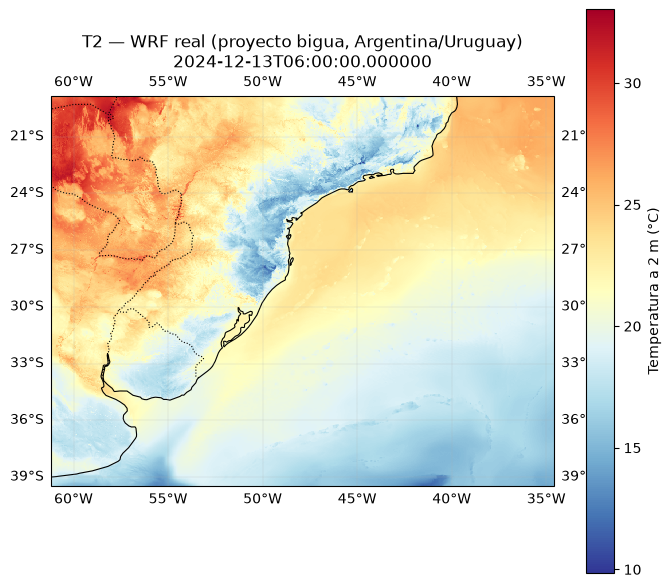

In [2]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

t2_celsius = ds["T2"].isel(Time=0) - 273.15
fecha_hora = str(ds["Time"].isel(Time=0).values)

extent = [float(ds.XLONG.min()), float(ds.XLONG.max()), float(ds.XLAT.min()), float(ds.XLAT.max())]

fig = plt.figure(figsize=(7, 6))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent(extent, crs=ccrs.PlateCarree())

malla = ax.pcolormesh(
    ds["XLONG"], ds["XLAT"], t2_celsius,
    transform=ccrs.PlateCarree(), cmap="RdYlBu_r", shading="auto",
)
ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linestyle=":", linewidth=0.8)
ax.gridlines(draw_labels=True, linewidth=0.3, alpha=0.5)

cbar = plt.colorbar(malla, ax=ax, orientation="vertical", pad=0.05)
cbar.set_label("Temperatura a 2 m (°C)")
ax.set_title(f"T2 — WRF real (proyecto bigua, Argentina/Uruguay)\n{fecha_hora}")

fig.tight_layout()
plt.savefig("mapa_temperatura.png", dpi=100)
plt.show()

## Ejercicio 3 — Campo de viento (40 min)

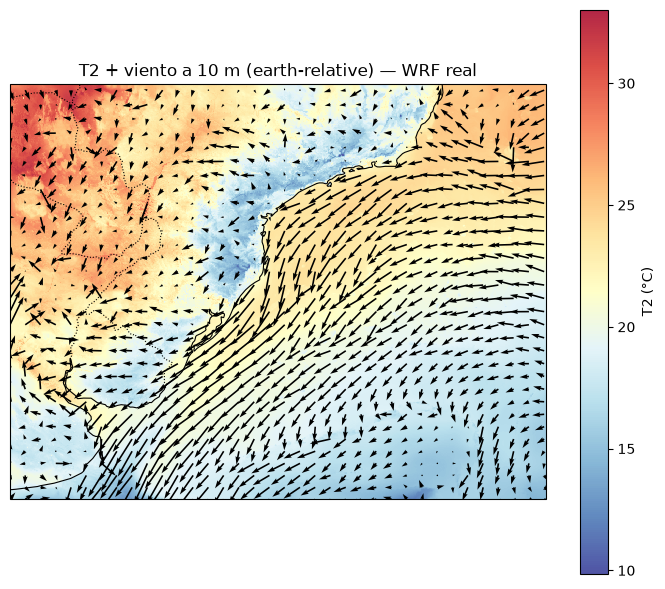

In [3]:
fig = plt.figure(figsize=(7, 6))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent(extent, crs=ccrs.PlateCarree())

malla = ax.pcolormesh(
    ds["XLONG"], ds["XLAT"], t2_celsius,
    transform=ccrs.PlateCarree(), cmap="RdYlBu_r", shading="auto", alpha=0.85,
)
ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linestyle=":", linewidth=0.8)

paso = 25  # submuestreo: la grilla real es de 786x879, demasiadas flechas para verlas todas
ax.quiver(
    ds["XLONG"].values[::paso, ::paso], ds["XLAT"].values[::paso, ::paso],
    ds["wind_east_10"].isel(Time=0).values[::paso, ::paso],
    ds["wind_north_10"].isel(Time=0).values[::paso, ::paso],
    transform=ccrs.PlateCarree(), scale=200, width=0.003,
)

cbar = plt.colorbar(malla, ax=ax, orientation="vertical", pad=0.05)
cbar.set_label("T2 (°C)")
ax.set_title("T2 + viento a 10 m (earth-relative) — WRF real")
fig.tight_layout()
plt.savefig("mapa_viento.png", dpi=100)
plt.show()

## Ejercicio 4 — Refuerzo: otro producto real de WRF, a niveles de presión (35 min)

Los Ejercicios 1-3 usaron `wrfout` **crudo**, en la coordenada vertical eta
nativa del modelo (Ejercicio de teoría, punto 1). En la práctica real casi
nunca se analiza el `wrfout` crudo directamente para mapas sinópticos —se
post-procesa primero a **niveles de presión estándar** (1000, 850, 700,
500, 300, 200 hPa, entre otros), con una herramienta externa al curso (acá,
un post-proceso tipo UPP). El resultado (`wrfpress_muestra.nc`, mismo
dominio y misma corrida real que el `wrfout` de arriba) es mucho más
parecido a un mapa sinóptico de manual: geopotencial + viento en un nivel
fijo, comparable directamente con productos de ERA5/GFS del Módulo 3.

In [4]:
ds_press = xr.open_dataset("../../../data/grid_muestra/wrfpress_muestra.nc")
print("Niveles de presión disponibles (hPa):", ds_press["pressure_level"].values.tolist())
print("Variables:", list(ds_press.data_vars))

Niveles de presión disponibles (hPa): [1000.0, 850.0, 700.0, 500.0, 300.0, 200.0]
Variables: ['GHT_PL', 'T_PL', 'U_PL', 'V_PL', 'RH_PL', 'Times']


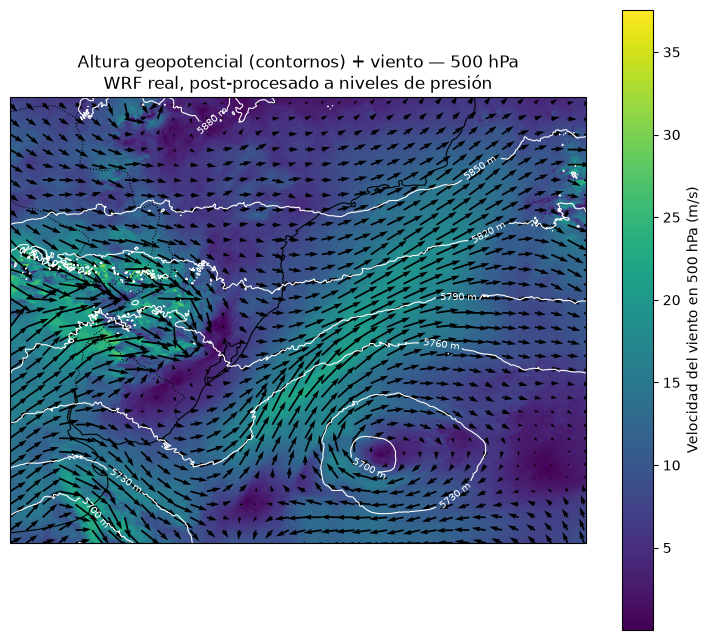

In [5]:
nivel = 500  # hPa -- nivel clasico para ver la onda larga de la circulacion media troposferica
d500 = ds_press.sel(pressure_level=nivel).isel(Time=0)
velocidad = np.sqrt(d500["U_PL"]**2 + d500["V_PL"]**2)

fig = plt.figure(figsize=(7.5, 6.5))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent(extent, crs=ccrs.PlateCarree())

sombreado = ax.pcolormesh(d500["XLONG"], d500["XLAT"], velocidad,
                           transform=ccrs.PlateCarree(), cmap="viridis", shading="auto")
contornos = ax.contour(d500["XLONG"], d500["XLAT"], d500["GHT_PL"],
                        colors="white", linewidths=0.8, transform=ccrs.PlateCarree())
ax.clabel(contornos, inline=True, fontsize=7, fmt="%d m")
ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linestyle=":", linewidth=0.8)

paso = 25
ax.quiver(d500["XLONG"].values[::paso, ::paso], d500["XLAT"].values[::paso, ::paso],
          d500["U_PL"].values[::paso, ::paso], d500["V_PL"].values[::paso, ::paso],
          transform=ccrs.PlateCarree(), scale=400, width=0.003, color="black")

cbar = plt.colorbar(sombreado, ax=ax, orientation="vertical", pad=0.05)
cbar.set_label(f"Velocidad del viento en {nivel} hPa (m/s)")
ax.set_title(f"Altura geopotencial (contornos) + viento — {nivel} hPa\nWRF real, post-procesado a niveles de presión")
fig.tight_layout()
plt.show()

**Un tipo de gráfico distinto: perfil vertical en un punto.** Todos los
mapas anteriores fijan un nivel y varían el espacio. Un perfil vertical
hace lo opuesto: fija un punto y varía el nivel — la forma más directa de
ver cómo cambia una variable con la altura, sin necesidad de un mapa.

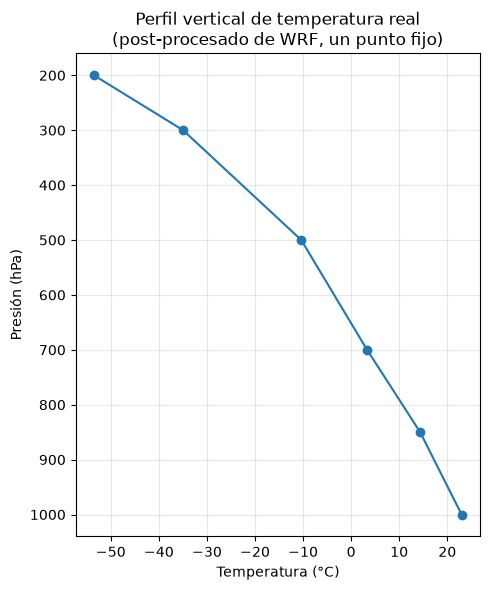

Temperatura por nivel (°C): [23.0, 14.4, 3.3, -10.4, -35.0, -53.5] hPa: [1000.0, 850.0, 700.0, 500.0, 300.0, 200.0]


In [6]:
lat_punto, lon_punto = -34.6, -58.4  # Buenos Aires, dentro del dominio real

d0 = ds_press.isel(Time=0)
dist2 = (d0["XLAT"] - lat_punto)**2 + (d0["XLONG"] - lon_punto)**2
iy, ix = np.unravel_index(np.argmin(dist2.values), dist2.shape)
perfil = d0.isel(south_north=iy, west_east=ix)

fig, ax = plt.subplots(figsize=(5, 6))
ax.plot(perfil["T_PL"] - 273.15, perfil["pressure_level"], marker="o")
ax.invert_yaxis()  # presion decrece hacia arriba -- convencion meteorologica
ax.set_xlabel("Temperatura (°C)")
ax.set_ylabel("Presión (hPa)")
ax.set_title("Perfil vertical de temperatura real\n(post-procesado de WRF, un punto fijo)")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

print("Temperatura por nivel (°C):",
      [round(float(t - 273.15), 1) for t in perfil["T_PL"].values], "hPa:",
      perfil["pressure_level"].values.tolist())

## Cierre

Entregable del día: este notebook + `mapa_temperatura.png` y
`mapa_viento.png`. Continuar con
[`03_practica_dia7_series.ipynb`](03_practica_dia7_series.ipynb).